# Development of an End-to-End NLP Pipeline for Customer Feedback
Intelligence and Sentiment Driven Decision Support

**Dataset:** Women's Clothing E-Commerce Reviews (real customer reviews)

**Run environment:** Google Colab with a **T4 GPU**. The T4 has
about 16 GB of memory, so I use a batch size of 16 for training in Task 4.

The dataset is loaded from the Hugging Face Hub, so no file upload is needed. It is real, unsanitised text: I do not fix the spelling or the punctuation of the reviews.

## Environment Setup

First I install the libraries. Then I import them, print the version of every library.


In [1]:
# Install the libraries that Colab does not already have and small model for spaCy.
!pip install -q datasets gensim sentence-transformers transformers accelerate gradio
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 59.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
# Import tools.
import re
import random
import time
from collections import Counter
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch

# Fix the random seed so the results are the same every time.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if there is one, otherwise use the CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found. Task 4 will be very slow on CPU.")

Device: cuda
GPU: Tesla T4


In [3]:
# Import the NLP libraries.
import sys
import matplotlib
import sklearn
import nltk
import spacy
import gensim
import sentence_transformers
import transformers
import datasets
import accelerate
import gradio

# Print the version of library.
versions = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
    "nltk": nltk.__version__,
    "spacy": spacy.__version__,
    "gensim": gensim.__version__,
    "sentence-transformers": sentence_transformers.__version__,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "accelerate": accelerate.__version__,
    "torch": torch.__version__,
    "gradio": gradio.__version__,
}
version_table = pd.DataFrame(list(versions.items()), columns=["Library", "Version"])
display(version_table)

,Library,Version
0,python,3.13.15
1,numpy,2.1.3
2,pandas,2.2.3
3,matplotlib,3.10.0
4,scikit-learn,1.6.1
5,nltk,3.9.1
6,spacy,3.8.16
7,gensim,4.4.0
8,sentence-transformers,5.7.0
9,transformers,5.17.0


In [4]:
# NLTK data (tokenizer data, stop words and WordNet for lemmatization).
for package in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(package, quiet=True)

# Load the tools from NLTK.
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Load the model of spaCy.
nlp = spacy.load("en_core_web_sm")
print("spaCy pipeline steps:", nlp.pipe_names)

spaCy pipeline steps: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## 1. Dataset

**Name:** Women's Clothing E-Commerce Reviews
**Source:** Hugging Face Hub, `saattrupdan/womens-clothing-ecommerce-reviews`
**Link:** https://huggingface.co/datasets/saattrupdan/womens-clothing-ecommerce-reviews

The label `recommended_ind` is 1 when the customer recommends the item and 0 when they do not. I treat 0 as a complaint. The column `department_name` is used for the fairness check in Task 5.

These are real reviews, not synthetic text. I do not edit the review text in this notebook. The cells below show it exactly as stored.

In [5]:
# Import the datasets from the Hugging Face Hub.
from datasets import load_dataset

hf_dataset = load_dataset("saattrupdan/womens-clothing-ecommerce-reviews")

# Join the parts into one table.
df = pd.concat([
    hf_dataset["train"].to_pandas(),
    hf_dataset["val"].to_pandas(),
    hf_dataset["test"].to_pandas(),
], ignore_index=True)

# Remove the rows that have no review text.
df = df.dropna(subset=["review_text"]).reset_index(drop=True)

# Give the main text column name.
df["text"] = df["review_text"]
df = df[["text", "rating", "recommended_ind", "positive_feedback_count",
         "age", "division_name", "department_name", "class_name"]]

print("Dataset shape:", df.shape)
display(df.head())

README.md:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

data/train-00000-of-00001-44ddebcb331919(…): reconstructing file:   0%|          |  0.00B / 3.97MB            

data/train-00000-of-00001-44ddebcb331919(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-90b9c3d0edf6fc3(…): reconstructing file:   0%|          |  0.00B /  192kB            

data/test-00000-of-00001-90b9c3d0edf6fc3(…): downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/20641 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset shape: (22641, 8)


,text,rating,recommended_ind,positive_feedback_count,age,division_name,department_name,class_name
0,I loved this shirt until the first time i wash...,1,0,0,39,General,Tops,Knits
1,"This sweater was unflattering me, very boxy an...",3,0,0,44,General,Tops,Sweaters
2,I fell in love with these bottoms at first sit...,5,1,2,41,General,Bottoms,Pants
3,I love the dress! i purchased this dress to w...,5,1,0,34,General,Dresses,Dresses
4,I fell in love with this dress when i saw it o...,5,1,0,46,General Petite,Dresses,Dresses


In [6]:
# Check the raw data before any cleaning.
print("Missing values per column:")
print(df.isna().sum())

print("\nDuplicate review texts:", df["text"].duplicated().sum())

# Look at the label we want to predict.
print("\nrecommended_ind counts (1 = recommended, 0 = not recommended):")
print(df["recommended_ind"].value_counts())
print("\nAs a share of all reviews:")
print(df["recommended_ind"].value_counts(normalize=True).round(3))

Missing values per column:
text                       0
rating                     0
recommended_ind            0
positive_feedback_count    0
age                        0
division_name              0
department_name            0
class_name                 0
dtype: int64

Duplicate review texts: 7

recommended_ind counts (1 = recommended, 0 = not recommended):
recommended_ind
1    18540
0     4101
Name: count, dtype: int64

As a share of all reviews:
recommended_ind
1    0.819
0    0.181
Name: proportion, dtype: float64


The two classes are not balanced. So plain accuracy can look good even if the model misses the complaints. I will look at precision, recall and F1 for each class, not only accuracy.

### Looking at the raw, unsanitised text

Before any cleaning, I print some reviews exactly as the customers wrote them. I use `repr` so that extra spaces and special characters are visible. Then I count how many reviews contain typical "messy text" problems. These problems are the reason why preprocessing is needed.

In [7]:
# Print 5 random raw reviews exactly as they are stored.
for text in df["text"].sample(5, random_state=SEED):
    print(repr(text), "\n")

'This vest is simply amazing. i wear all black and throw this on top and it becomes the perfect outfit. i love that the top portion of the vest is light weight and thr fur portion is so soft. tts' 

"Absolutely gorgeous! i bought my regular size m and while it's a little wide in the shoulders, it drapes beautifully. because i'm so short, i found the sleeves too long so i took it to my dressmaker and she shortened the sleeves about two inches so it's still elbow length and while i was there, she put in two small darts in the back so make it less boxy for my frame. can't wait to wear it - it's a beautiful material and i love the combo of the metallic sheen and velvet. so elegant. very gatsby," 

'I love this dress and had so hoped to wear it to a wedding in june. the fabric is a perfect weight, very nice cotton, i only wish i could have kept it. i am 5\'3", 133 lbs and usually wear a size 6 which is what i ordered. it was fine in the skirt but the top was at least a size if not two sizes

In [8]:
# Count how many reviews have each kind of messy text.
noise_checks = {
    "Two or more spaces in a row": r"\s{2,}",
    "Words written in ALL CAPS (3+ letters)": r"\b[A-Z]{3,}\b",
    "Contains digits": r"\d",
    "Repeated ! or ? (for example !!!)": r"[!?]{2,}",
    "Stretched letters (for example sooo)": r"([A-Za-z])\1{2,}",
    "Non-ASCII characters": r"[^\x00-\x7F]",
    "No space after a full stop (for example fit.it)": r"[a-z]\.[a-z]",
}

noise_rows = []
for name, pattern in noise_checks.items():
    count = df["text"].str.contains(pattern, regex=True).sum()
    noise_rows.append({"Problem": name, "Reviews": count, "Share of reviews": f"{count / len(df):.1%}"})

display(pd.DataFrame(noise_rows))

,Problem,Reviews,Share of reviews
0,Two or more spaces in a row,2724,12.0%
1,Words written in ALL CAPS (3+ letters),0,0.0%
2,Contains digits,8790,38.8%
3,Repeated ! or ? (for example !!!),1063,4.7%
4,Stretched letters (for example sooo),300,1.3%
5,Non-ASCII characters,30,0.1%
6,No space after a full stop (for example fit.it),282,1.2%


## Task 1: Preprocessing and Exploratory Analysis

In this task I look at the raw reviews, clean them with NLTK, run spaCy (including named entity recognition), and draw some charts.

### 1.1 Exploring the raw data

Before cleaning anything, I look at three things: how long the reviews are, how the star ratings are spread, and which departments get the most reviews.

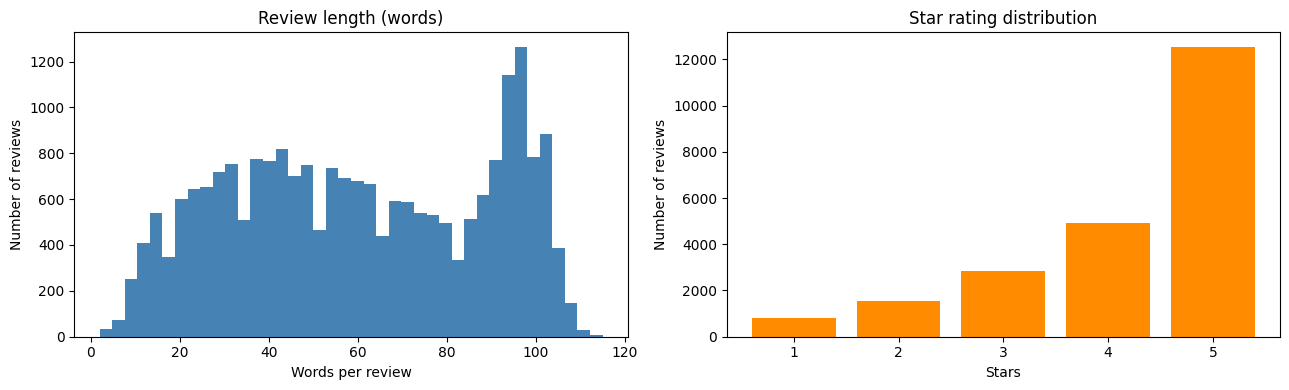

count    22641.0
mean        60.2
std         28.5
min          2.0
25%         36.0
50%         59.0
75%         88.0
max        115.0
Name: review_length_words, dtype: float64


In [9]:
# Count the words in every review.
df["review_length_words"] = df["text"].str.split().str.len()

# Draw two charts next to each other.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Chart 1: how long are the reviews?
axes[0].hist(df["review_length_words"], bins=40, color="steelblue")
axes[0].set_title("Review length (words)")
axes[0].set_xlabel("Words per review")
axes[0].set_ylabel("Number of reviews")

# Chart 2: how many reviews for each star rating?
rating_counts = df["rating"].value_counts().sort_index()
axes[1].bar(rating_counts.index.astype(str), rating_counts.values, color="darkorange")
axes[1].set_title("Star rating distribution")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()

print(df["review_length_words"].describe().round(1))

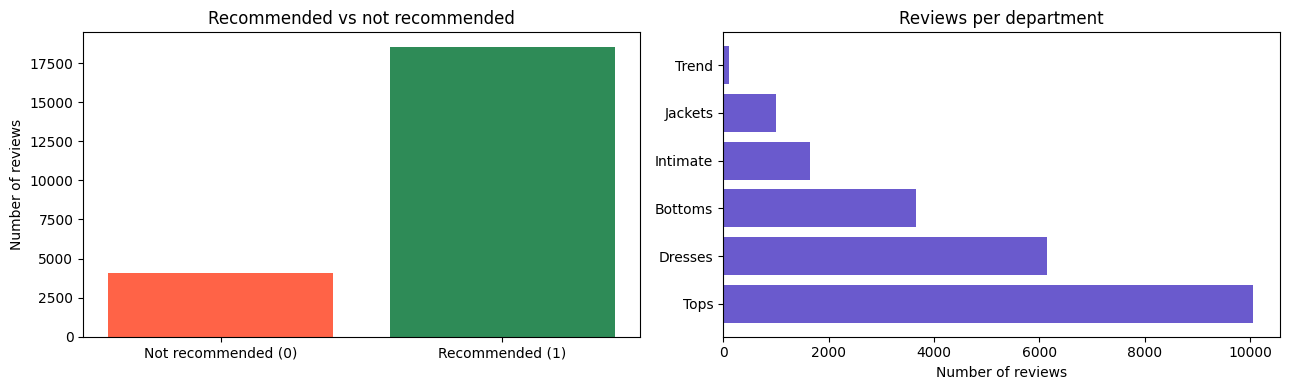

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Chart 1: recommended vs not recommended.
rec_counts = df["recommended_ind"].value_counts().sort_index()
axes[0].bar(["Not recommended (0)", "Recommended (1)"], rec_counts.values, color=["tomato", "seagreen"])
axes[0].set_title("Recommended vs not recommended")
axes[0].set_ylabel("Number of reviews")

# Chart 2: reviews per department.
dept_counts = df["department_name"].value_counts()
axes[1].barh(dept_counts.index, dept_counts.values, color="slateblue")
axes[1].set_title("Reviews per department")
axes[1].set_xlabel("Number of reviews")

plt.tight_layout()
plt.show()

Average words per review:
recommended_ind
0    62.0
1    59.8
Name: review_length_words, dtype: float64


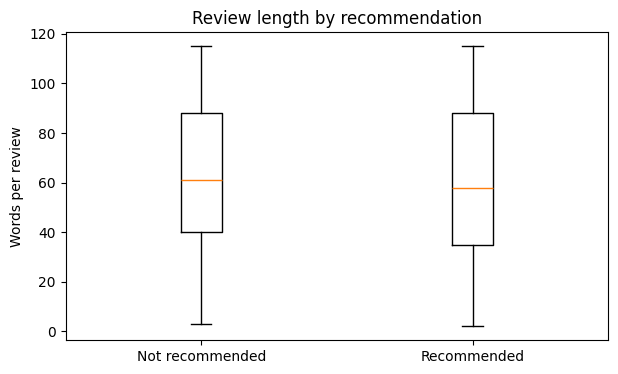

In [11]:
# Compare the average length of the two groups.
length_by_label = df.groupby("recommended_ind")["review_length_words"].mean().round(1)
print("Average words per review:")
print(length_by_label)

# Boxplot of the two groups.
plt.figure(figsize=(7, 4))
groups = [df[df["recommended_ind"] == 0]["review_length_words"],
          df[df["recommended_ind"] == 1]["review_length_words"]]
plt.boxplot(groups)
plt.xticks([1, 2], ["Not recommended", "Recommended"])
plt.title("Review length by recommendation")
plt.ylabel("Words per review")
plt.show()

### 1.2 Preprocessing with NLTK

My cleaning function has five steps:

1. Lowercase the text.
2. Split it into tokens with NLTK's `word_tokenize`.
3. Remove stop words.
4. Remove tokens that are only one letter.
5. Lemmatize each token with `WordNetLemmatizer`.

**One thing to explain.** The default NLTK stop word list contains negation words like "not", "no" and "never". For complaint detection these words matter a lot, because "not good" means the opposite of "good". So I take the negation words out of the stop word list, so that they are kept. I will test this choice in section 1.6.

In [12]:
# The default English stop words from NLTK.
default_stop_words = set(stopwords.words("english"))

# Negation words that we do NOT want to remove.
negation_words = {"no", "not", "nor", "never", "n't"}

my_stop_words = default_stop_words - negation_words

lemmatizer = WordNetLemmatizer()

print("Default stop words:", len(default_stop_words))
print("My stop words     :", len(my_stop_words))

Default stop words: 198
My stop words     : 195


In [13]:
# Define the function that cleans one review.
def nltk_preprocess(text, stop_list=my_stop_words):
    text = text.lower().replace("’", "'")
    text = re.sub(r"([.,!?;])", r" \1 ", text)
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() or t == "n't"]
    tokens = [t for t in tokens if t not in stop_list and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

# Apply the function to every review.
df["nltk_tokens"] = df["text"].apply(nltk_preprocess)
df["nltk_token_count"] = df["nltk_tokens"].apply(len)

display(df[["text", "nltk_tokens"]].head())

example_review = df.loc[3, "text"]
print("RAW TEXT:")
print(example_review)
print("\nAFTER NLTK PREPROCESSING:")
print(df.loc[3, "nltk_tokens"])

,text,nltk_tokens
0,I loved this shirt until the first time i wash...,"[loved, shirt, first, time, washed, shrunk, mu..."
1,"This sweater was unflattering me, very boxy an...","[sweater, unflattering, boxy, not, fall, like,..."
2,I fell in love with these bottoms at first sit...,"[fell, love, bottom, first, site, little, worr..."
3,I love the dress! i purchased this dress to w...,"[love, dress, purchased, dress, wear, honeymoo..."
4,I fell in love with this dress when i saw it o...,"[fell, love, dress, saw, online, got, soon, we..."


RAW TEXT:
I love the dress!  i purchased this dress to wear on my honeymoon to paris.  it made me feel like a princess walking around the gardens of versalles while wearing it!

AFTER NLTK PREPROCESSING:
['love', 'dress', 'purchased', 'dress', 'wear', 'honeymoon', 'paris', 'made', 'feel', 'like', 'princess', 'walking', 'around', 'garden', 'versalles', 'wearing']


### 1.3 Preprocessing and named entity recognition with spaCy

spaCy does tokenization, lemmatization and named entity recognition (NER) in one pipeline. NER finds things like places, money amounts and dates in the text.

I use `nlp.pipe()` because it processes many texts in batches. That is faster than calling `nlp()` one review at a time.

In [14]:
# Take a random sample of reviews.
SPACY_SAMPLE_SIZE = 3000
spacy_sample = df.sample(n=SPACY_SAMPLE_SIZE, random_state=SEED)

spacy_lemmas = []
spacy_entities = []

# Run spaCy on the reviews in batches.
for doc in nlp.pipe(spacy_sample["text"].tolist(), batch_size=64):
    lemmas = [tok.lemma_.lower() for tok in doc
              if tok.is_alpha and not tok.is_stop and not tok.is_punct]
    spacy_lemmas.append(lemmas)
    spacy_entities.append([(ent.text, ent.label_) for ent in doc.ents])

spacy_sample["spacy_lemmas"] = spacy_lemmas
spacy_sample["spacy_entities"] = spacy_entities
spacy_sample["spacy_token_count"] = spacy_sample["spacy_lemmas"].apply(len)

display(spacy_sample[["text", "spacy_lemmas", "spacy_entities"]].head())

,text,spacy_lemmas,spacy_entities
12888,This vest is simply amazing. i wear all black ...,"[vest, simply, amazing, wear, black, throw, pe...",[]
19134,Absolutely gorgeous! i bought my regular size ...,"[absolutely, gorgeous, buy, regular, size, m, ...","[(about two inches, QUANTITY), (two, CARDINAL)]"
18051,I love this dress and had so hoped to wear it ...,"[love, dress, hop, wear, wedding, june, fabric...","[(june, DATE), (5'3, MONEY), (133, CARDINAL), ..."
10263,"Nice dress, but the leather seats of my car we...","[nice, dress, leather, seat, car, ruin, sharp,...",[]
7097,Love this vest. it is super soft and cozy yet ...,"[love, vest, super, soft, cozy, fit, lay, bulk...",[]


,Entity type,Count
1,CARDINAL,1765
2,DATE,915
5,ORDINAL,216
7,ORG,124
0,QUANTITY,117
3,MONEY,111
10,PERSON,81
8,GPE,70
9,TIME,69
6,PERCENT,41


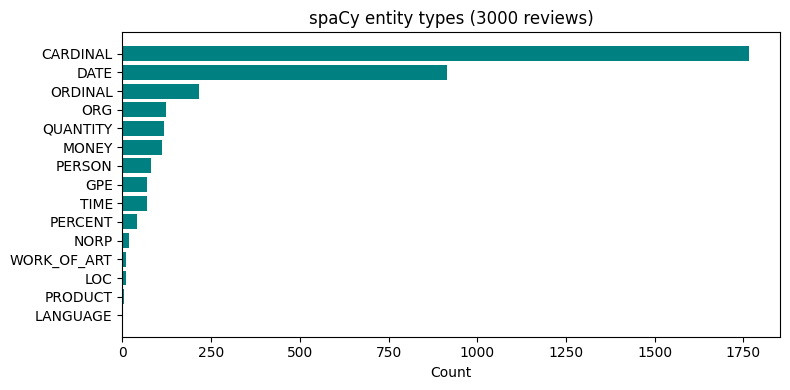

In [15]:
# Put all entities of all reviews into one list.
all_entities = [ent for row in spacy_entities for ent in row]

# Count how often each entity type appears.
entity_type_counts = Counter(label for text, label in all_entities)
ent_df = pd.DataFrame(entity_type_counts.items(), columns=["Entity type", "Count"])
ent_df = ent_df.sort_values("Count", ascending=False)
display(ent_df)

plt.figure(figsize=(8, 4))
plt.barh(ent_df["Entity type"][::-1], ent_df["Count"][::-1], color="teal")
plt.title(f"spaCy entity types ({SPACY_SAMPLE_SIZE} reviews)")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

In [16]:
# Look at a few real examples of each common entity type, to judge the quality by eye.
for label in ["GPE", "ORG", "MONEY", "DATE", "CARDINAL", "PRODUCT"]:
    examples = [text for text, lab in all_entities if lab == label][:6]
    print(label, ":", examples)

GPE : ['cali', 'florida', 'taza', 'xxs', 'florida', 'panama']
ORG : ['boots.very', 'navy', 'ag', 'Super', 'Ag', 'ag']
MONEY : ["5'3", "5'3", '150#', '$$$', '100#', '102- 104 pounds']
DATE : ['june', 'years', 'spring', 'the spring', '2008', '16']
CARDINAL : ['two', '133', '6', 'two', '32', '6']
PRODUCT : ['Classic', 'mosaic', 'Classic']


### 1.4 Word frequency

A frequency chart shows what customers talk about most. I use the cleaned NLTK tokens and `Counter`.

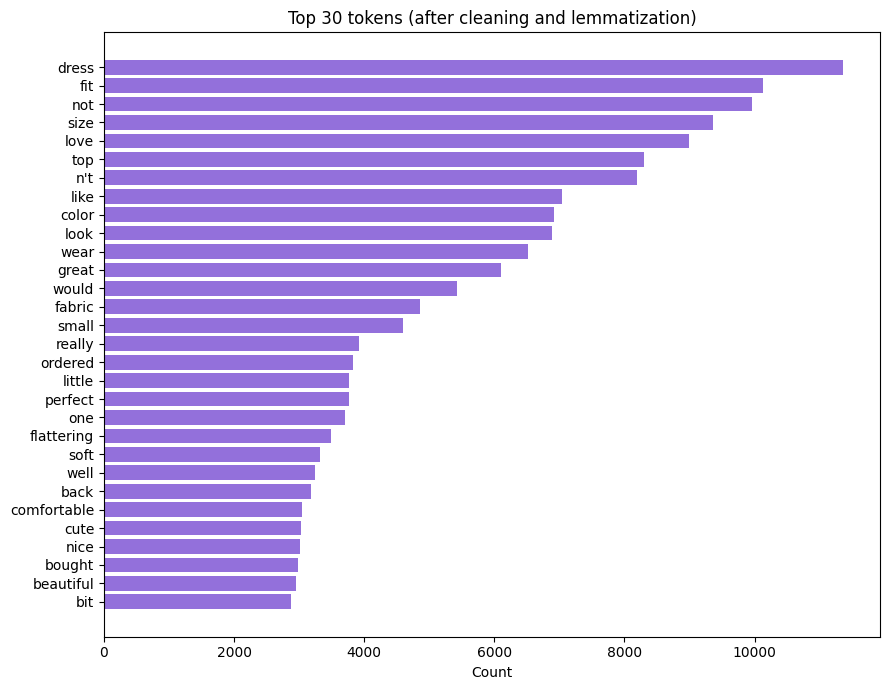

In [17]:
# Put every token of every review into one long list and count them.
all_tokens = [tok for tokens in df["nltk_tokens"] for tok in tokens]
word_freq = Counter(all_tokens)

# Take the 30 most common tokens.
top_30 = word_freq.most_common(30)
words = [w for w, c in top_30]
counts = [c for w, c in top_30]

plt.figure(figsize=(9, 7))
plt.barh(words[::-1], counts[::-1], color="mediumpurple")
plt.title("Top 30 tokens (after cleaning and lemmatization)")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

In [18]:
# Compare the most common tokens in the two groups.
not_rec_tokens = [tok for tokens in df[df["recommended_ind"] == 0]["nltk_tokens"] for tok in tokens]
rec_tokens = [tok for tokens in df[df["recommended_ind"] == 1]["nltk_tokens"] for tok in tokens]

print("Top 15 in NOT recommended reviews:")
print([w for w, c in Counter(not_rec_tokens).most_common(15)])
print("\nTop 15 in recommended reviews:")
print([w for w, c in Counter(rec_tokens).most_common(15)])

Top 15 in NOT recommended reviews:
['not', 'dress', "n't", 'like', 'top', 'look', 'fit', 'would', 'size', 'fabric', 'back', 'color', 'love', 'small', 'really']

Top 15 in recommended reviews:
['dress', 'fit', 'love', 'size', 'not', 'top', "n't", 'color', 'wear', 'great', 'look', 'like', 'would', 'small', 'fabric']


### Common word pairs (complaint themes)

Single words are not always clear. Word pairs show the themes better, for example "too small". I count the most common word pairs in each group with `CountVectorizer`.

In [19]:
# Import the tool that counts words and word pairs.
from sklearn.feature_extraction.text import CountVectorizer

def top_bigrams(token_lists, n=10, min_df=5):
    texts = [" ".join(tokens) for tokens in token_lists]
    counter = CountVectorizer(ngram_range=(2, 2), token_pattern=r"\S+", min_df=min_df)
    counts = counter.fit_transform(texts)
    totals = np.asarray(counts.sum(axis=0)).ravel()
    names = counter.get_feature_names_out()
    top = np.argsort(totals)[::-1][:n]
    return [(names[i], int(totals[i])) for i in top]

print("Top word pairs in NOT recommended reviews:")
print(top_bigrams(df[df["recommended_ind"] == 0]["nltk_tokens"]))
print("\nTop word pairs in recommended reviews:")
print(top_bigrams(df[df["recommended_ind"] == 1]["nltk_tokens"]))

Top word pairs in NOT recommended reviews:
[('look like', 277), ('wanted love', 243), ('going back', 215), ('not flattering', 195), ('looked like', 187), ("could n't", 169), ("ca n't", 157), ('really wanted', 150), ("n't work", 138), ('made look', 136)]

Top word pairs in recommended reviews:
[('true size', 1215), ('fit perfectly', 1030), ('look great', 828), ("ca n't", 756), ('love dress', 648), ('usually wear', 586), ('fit well', 569), ('fit great', 544), ('look like', 527), ('love top', 511)]


### 1.5 NLTK vs spaCy

The table below compares the two libraries on the same 3,000 reviews. The numbers are calculated by the code, not typed by hand.

In [20]:
# Lemmatization example: the same words in both libraries.
test_words = ["running", "better", "dresses", "bought"]
nltk_lemmas = [lemmatizer.lemmatize(w) for w in test_words]
spacy_lemmas_test = [nlp(w)[0].lemma_ for w in test_words]
lemma_example = pd.DataFrame({"word": test_words, "NLTK lemma": nltk_lemmas, "spaCy lemma": spacy_lemmas_test})
display(lemma_example)

# Tokens before stop word removal: NLTK tokenizer and spaCy tokenizer on the same review.
sample_texts = spacy_sample["text"].tolist()
nltk_raw_counts = [len(word_tokenize(t.lower())) for t in sample_texts]
spacy_raw_counts = [len(nlp.tokenizer(t)) for t in sample_texts]

# Time both libraries on the same 3,000 reviews.
start_time = time.time()
_ = [nltk_preprocess(t) for t in sample_texts]
nltk_seconds = time.time() - start_time

start_time = time.time()
_ = list(nlp.pipe(sample_texts, batch_size=64))
spacy_seconds = time.time() - start_time

nltk_sample_tokens = df.loc[spacy_sample.index, "nltk_tokens"]

comparison = pd.DataFrame({
    "Aspect": [
        "Average tokens per review, before stop word removal",
        "Words in the default stop word list",
        "Average tokens per review, after cleaning (same 3,000 reviews)",
        "Vocabulary size (same 3,000 reviews)",
        "Time for the same 3,000 reviews (seconds)",
        "Named entity recognition",
        "Entity detection examples (first 5 found)",
        "Handling of negation words",
    ],
    "NLTK": [
        round(np.mean(nltk_raw_counts), 1),
        len(default_stop_words),
        round(nltk_sample_tokens.apply(len).mean(), 1),
        len(set(tok for tokens in nltk_sample_tokens for tok in tokens)),
        round(nltk_seconds, 1),
        "Not included in my pipeline",
        "None (NLTK has no ready-made NER step in my pipeline)",
        "I removed them from the stop word list myself, so they are kept",
    ],
    "spaCy": [
        round(np.mean(spacy_raw_counts), 1),
        len(nlp.Defaults.stop_words),
        round(spacy_sample["spacy_token_count"].mean(), 1),
        len(set(tok for tokens in spacy_lemmas for tok in tokens)),
        round(spacy_seconds, 1),
        "Built in (PERSON, ORG, GPE, MONEY, DATE and more)",
        str(all_entities[:5]),
        "Its default stop word list also contains words like 'not' and 'no'",
    ],
})
display(comparison)

,word,NLTK lemma,spaCy lemma
0,running,running,run
1,better,better,well
2,dresses,dress,dress
3,bought,bought,buy


,Aspect,NLTK,spaCy
0,"Average tokens per review, before stop word re...",70.3,70.9
1,Words in the default stop word list,198,326
2,"Average tokens per review, after cleaning (sam...",28.8,24.6
3,"Vocabulary size (same 3,000 reviews)",5043,4393
4,"Time for the same 3,000 reviews (seconds)",4.3,48.7
5,Named entity recognition,Not included in my pipeline,"Built in (PERSON, ORG, GPE, MONEY, DATE and more)"
6,Entity detection examples (first 5 found),None (NLTK has no ready-made NER step in my pi...,"[('about two inches', 'QUANTITY'), ('two', 'CA..."
7,Handling of negation words,"I removed them from the stop word list myself,...",Its default stop word list also contains words...


## Task 2: Classical NLP Baseline

The goal is to predict whether a review is **not recommended** (0, my complaint label) or **recommended** (1).

The plan has four parts:

1. Split the data into train and test sets (80% and 20%).
2. Turn the text into numbers with TF-IDF.
3. Train two models: Logistic Regression and Complement Naive Bayes.
4. Compare them with accuracy, precision, recall and F1, and read the wrong predictions.

I choose Complement Naive Bayes as the second model because it is made for text with unbalanced classes, and we studied it in the lectures.

In [21]:
# Import the tools for the classical models.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# X is the review text and y is the label.
X = df["text"]
y = df["recommended_ind"]

# Split into train and test. stratify keeps the same class share in both parts
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("Train size:", len(X_train_text), "| Test size:", len(X_test_text))
print("\nShare of each class in the train set:")
print(y_train.value_counts(normalize=True).round(3))

Train size: 18112 | Test size: 4529

Share of each class in the train set:
recommended_ind
1    0.819
0    0.181
Name: proportion, dtype: float64


In [22]:
# Turn the text into TF-IDF numbers.
# Note: stop_words is not set here, so that "not" and "no" are kept.
tfidf = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)

# Learn the vocabulary from the TRAIN text only, then transform both parts.
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print("TF-IDF matrix (train):", X_train_tfidf.shape)

TF-IDF matrix (train): (18112, 8000)


In [23]:
# A helper function that prints the metrics and draws the confusion matrix.
def evaluate_model(name, y_true, y_pred, cmap="Blues"):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")
    # Macro F1 gives the same weight to both classes.
    macro_f1 = precision_recall_fscore_support(y_true, y_pred, average="macro")[2]

    print("-----", name, "-----")
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision: {precision:.3f} (weighted)")
    print(f"Recall   : {recall:.3f} (weighted)")
    print(f"F1       : {f1:.3f} (weighted)")
    print(f"Macro F1 : {macro_f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=["Not recommended", "Recommended"]))

    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Not recommended", "Recommended"]).plot(cmap=cmap, values_format="d")
    plt.title("Confusion matrix: " + name)
    plt.show()

    return {"model": name, "accuracy": acc, "precision": precision,
            "recall": recall, "f1": f1, "macro_f1": macro_f1}

Training time: 1.0 seconds
----- Logistic Regression -----
Accuracy : 0.891
Precision: 0.911 (weighted)
Recall   : 0.891 (weighted)
F1       : 0.897 (weighted)
Macro F1 : 0.837

                 precision    recall  f1-score   support

Not recommended       0.65      0.87      0.74       820
    Recommended       0.97      0.90      0.93      3709

       accuracy                           0.89      4529
      macro avg       0.81      0.88      0.84      4529
   weighted avg       0.91      0.89      0.90      4529



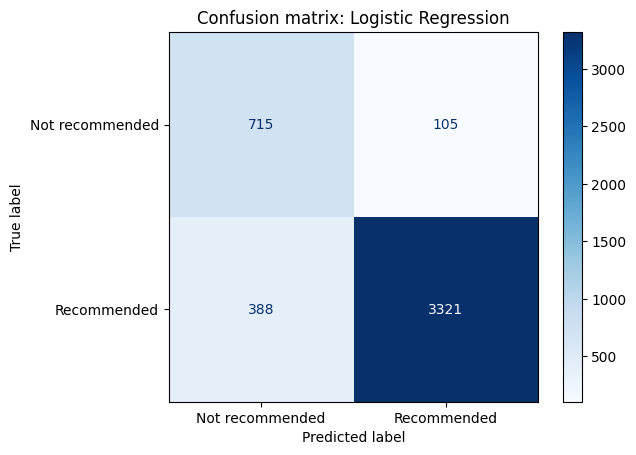

In [24]:
# Model 1: Logistic Regression.
# class_weight="balanced" gives more weight to the smaller class.
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
start_time = time.time()
logreg.fit(X_train_tfidf, y_train)
logreg_full_seconds = time.time() - start_time
print(f"Training time: {logreg_full_seconds:.1f} seconds")
logreg_preds = logreg.predict(X_test_tfidf)

logreg_results = evaluate_model("Logistic Regression", y_test, logreg_preds)

----- Complement Naive Bayes -----
Accuracy : 0.864
Precision: 0.902 (weighted)
Recall   : 0.864 (weighted)
F1       : 0.874 (weighted)
Macro F1 : 0.807

                 precision    recall  f1-score   support

Not recommended       0.58      0.89      0.70       820
    Recommended       0.97      0.86      0.91      3709

       accuracy                           0.86      4529
      macro avg       0.78      0.87      0.81      4529
   weighted avg       0.90      0.86      0.87      4529



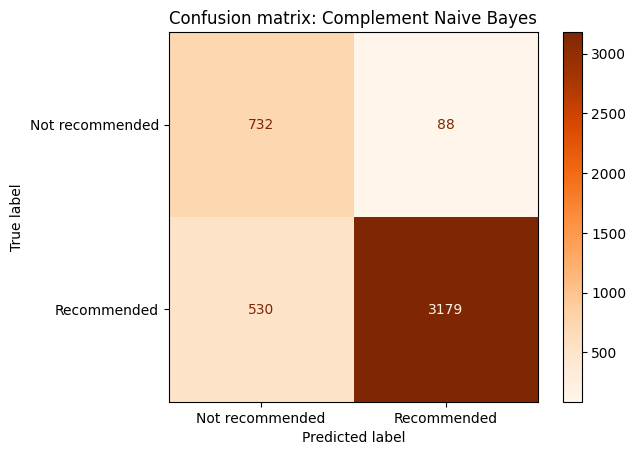

In [25]:
# Model 2: Complement Naive Bayes.
nb = ComplementNB()
nb.fit(X_train_tfidf, y_train)
nb_preds = nb.predict(X_test_tfidf)

nb_results = evaluate_model("Complement Naive Bayes", y_test, nb_preds, cmap="Oranges")

In [26]:
# Put the results of both models in one table.
classical_comparison = pd.DataFrame([logreg_results, nb_results]).set_index("model").round(3)
display(classical_comparison)

best_classical = classical_comparison["macro_f1"].idxmax()
print("Better macro F1 on this test set:", best_classical)

,accuracy,precision,recall,f1,macro_f1
model,,,,,
Logistic Regression,0.891,0.911,0.891,0.897,0.837
Complement Naive Bayes,0.864,0.902,0.864,0.874,0.807


Better macro F1 on this test set: Logistic Regression


In [27]:
# Which words push the Logistic Regression model towards each class?
feature_names = np.array(tfidf.get_feature_names_out())
coefs = logreg.coef_[0]

# Lowest weights point to class 0 (not recommended), highest to class 1 (recommended)
top_negative = feature_names[np.argsort(coefs)[:15]]
top_positive = feature_names[np.argsort(coefs)[-15:]]

print("Words pushing towards NOT recommended:")
print(list(top_negative))
print("\nWords pushing towards recommended:")
print(list(top_positive))

Words pushing towards NOT recommended:
['disappointed', 'to love', 'was', 'unflattering', 'huge', 'not', 'returned', 'cheap', 'returning', 'not flattering', 'back', 'going back', 'wanted to', 'looked', 'however']

Words pushing towards recommended:
['unique', 'comfy', 'flattering', 'bit', 'compliments', 'love this', 'soft', 'fits', 'comfortable', 'not too', 'little', 'with', 'great', 'perfect', 'love']


### Experiment: do simple NER features help?

I use spaCy to count the entities in every review (for example how many numbers, dates or money values it mentions). I add these 7 counts next to the TF-IDF features and train the same Logistic Regression again.

To join the two sets of features I use `hstack` from scipy, which puts sparse matrices side by side.

In [28]:
# Import the tool that joins matrices side by side.
from scipy.sparse import hstack, csr_matrix

entity_types = ["CARDINAL", "DATE", "MONEY", "GPE", "ORG", "PRODUCT", "PERSON"]

ner_rows = []
for doc in nlp.pipe(df["text"].tolist(), batch_size=64, disable=["parser", "lemmatizer"]):
    counts = Counter(ent.label_ for ent in doc.ents)
    ner_rows.append([counts.get(label, 0) for label in entity_types])

ner_features = pd.DataFrame(ner_rows, columns=entity_types, index=df.index)
display(ner_features.describe().round(2))

,CARDINAL,DATE,MONEY,GPE,ORG,PRODUCT,PERSON
count,22641.00,22641.0,22641.00,22641.00,22641.00,22641.00,22641.00
mean,0.60,0.3,0.03,0.02,0.04,0.00,0.03
std,1.05,0.6,0.19,0.16,0.22,0.03,0.18
min,0.00,0.0,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.0,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.0,0.00,0.00,0.00,0.00,0.00
75%,1.00,0.0,0.00,0.00,0.00,0.00,0.00
max,11.00,7.0,3.00,4.00,4.00,1.00,3.00


In [31]:
# Helper function to create summary rows.
def summary_row(model_name, y_true, y_pred):
    from sklearn.metrics import accuracy_score, precision_recall_fscore_support
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = precision_recall_fscore_support(y_true, y_pred, average="macro")[2]
    return {
        "Model": model_name,
        "Accuracy": round(acc, 3),
        "Macro F1": round(macro_f1, 3)
    }

# Put the TF-IDF features and the entity counts side by side.
from scipy.sparse import hstack, csr_matrix
X_train_ner = hstack([X_train_tfidf, csr_matrix(ner_features.loc[X_train_text.index].values)]).tocsr()
X_test_ner = hstack([X_test_tfidf, csr_matrix(ner_features.loc[X_test_text.index].values)]).tocsr()

logreg_ner = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
logreg_ner.fit(X_train_ner, y_train)
logreg_ner_preds = logreg_ner.predict(X_test_ner)

ner_table = pd.DataFrame([
    summary_row("TF-IDF only (my main model)", y_test, logreg_preds),
    summary_row("TF-IDF + entity counts", y_test, logreg_ner_preds),
])
display(ner_table)

diff = ner_table.loc[1, "Macro F1"] - ner_table.loc[0, "Macro F1"]
if diff > 0.005:
    print(f"The entity counts improved macro F1 by {diff:+.3f}.")
else:
    print(f"The entity counts did not clearly improve macro F1 (difference {diff:+.3f}).")

,Model,Accuracy,Macro F1
0,TF-IDF only (my main model),0.891,0.837
1,TF-IDF + entity counts,0.892,0.838


The entity counts did not clearly improve macro F1 (difference +0.001).


### Experiment: change the decision threshold

Logistic Regression gives a probability for every review. Until now a review was called a complaint when this probability was 0.5 or higher. A business may want to catch more complaints. So I try other cut-offs and look at complaint precision and recall. These cut-offs are tried on the test set to show the effect. They are not a tuned setting.

In [32]:
# Probability that a review is a complaint (class 0).
complaint_prob = logreg.predict_proba(X_test_tfidf)[:, 0]

threshold_rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7]:
    # A review is flagged as a complaint (0) when its probability is at or above the cut-off.
    flagged = np.where(complaint_prob >= cutoff, 0, 1)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, flagged, average=None)
    threshold_rows.append({
        "Cut-off": cutoff,
        "Reviews flagged as complaints": int((flagged == 0).sum()),
        "Complaint precision": round(precision[0], 3),
        "Complaint recall": round(recall[0], 3),
        "Accuracy": round(accuracy_score(y_test, flagged), 3),
    })

display(pd.DataFrame(threshold_rows))

,Cut-off,Reviews flagged as complaints,Complaint precision,Complaint recall,Accuracy
0,0.3,1621,0.486,0.961,0.809
1,0.4,1322,0.571,0.921,0.860
2,0.5,1103,0.648,0.872,0.891
3,0.6,919,0.717,0.804,0.907
4,0.7,716,0.779,0.680,0.907


### Check: is the result stable? (5-fold cross-validation)

All results so far come from one split. I repeat the training with 5-fold cross-validation on the **training set only**. A `Pipeline` puts the TF-IDF step inside every fold, so the validation part of each fold is never used to learn the vocabulary.

In [33]:
# Import the tools for cross-validation and the pipeline.
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "Complement Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)),
        ("classifier", ComplementNB()),
    ]),
}

cv_rows = []
for name, model_pipeline in cv_models.items():
    fold_scores = cross_val_score(model_pipeline, X_train_text, y_train, cv=cv, scoring="f1_macro")
    cv_rows.append({
        "Model": name,
        "Fold scores": [round(s, 3) for s in fold_scores],
        "Mean macro F1": round(fold_scores.mean(), 3),
        "Std": round(fold_scores.std(), 3),
    })

display(pd.DataFrame(cv_rows))

,Model,Fold scores,Mean macro F1,Std
0,Logistic Regression,"[0.824, 0.828, 0.827, 0.821, 0.814]",0.823,0.005
1,Complement Naive Bayes,"[0.813, 0.813, 0.813, 0.807, 0.803]",0.810,0.004


### Misclassified examples

Now I read some reviews that the Logistic Regression model got wrong. There are two kinds of mistakes:

- **False positive for "recommended":** the true label is 0 but the model says 1. A real complaint is missed.
- **False negative for "recommended":** the true label is 1 but the model says 0. A happy customer is flagged as a complaint.

In [34]:
# Put the test texts, true labels, predictions and the predicted probability in one table.
results_df = pd.DataFrame({
    "text": X_test_text.values,
    "true_label": y_test.values,
    "predicted_label": logreg_preds,
    "prob_recommended": logreg.predict_proba(X_test_tfidf)[:, 1].round(3),
})

wrong = results_df[results_df["true_label"] != results_df["predicted_label"]]
print(f"Wrong predictions: {len(wrong)} out of {len(results_df)} ({len(wrong) / len(results_df):.1%})")

# Missed complaints: true 0, predicted 1
missed_complaints = wrong[wrong["true_label"] == 0]
# Wrongly flagged: true 1, predicted 0
wrongly_flagged = wrong[wrong["true_label"] == 1]
print("Missed complaints (true 0, predicted 1):", len(missed_complaints))
print("Wrongly flagged   (true 1, predicted 0):", len(wrongly_flagged))

print("\n=== 3 MISSED COMPLAINTS ===")
for _, row in missed_complaints.sample(3, random_state=7).iterrows():
    print(f"- P(recommended) = {row['prob_recommended']}")
    print(" ", row["text"], "\n")

print("=== 3 WRONGLY FLAGGED HAPPY REVIEWS ===")
for _, row in wrongly_flagged.sample(3, random_state=7).iterrows():
    print(f"- P(recommended) = {row['prob_recommended']}")
    print(" ", row["text"], "\n")

Wrong predictions: 493 out of 4529 (10.9%)
Missed complaints (true 0, predicted 1): 105
Wrongly flagged   (true 1, predicted 0): 388

=== 3 MISSED COMPLAINTS ===
- P(recommended) = 0.525
  What an adorable and frustrating skirt! i'm not a large person: 32d-26-36. and i ordered my normal size small. this is a pull on skirt, and the waist opening could not accommodate either my shoulders or my hips. in most retailer clothes, i'm either a size 2 or 4; i have to agree with the other reviewer. there is no way to put this item on. 

- P(recommended) = 0.712
  When i saw this online i immediately put it on my "must buy" list. i hate paying the exorbitant shipping fees retailer charges so i was waiting until i could get to my local store, in the meantime it looks like it has sold out online but i am sure it will be back in stock soon. luckily, my b&m store had it and i am so glad i didn't waste my money or time ordering it online. this could have been great but once again antho missed the mark

## Task 3: Semantic Embeddings for Retrieval and Similarity

TF-IDF only matches exact words. "Too small" and "runs tiny" share no words, so TF-IDF treats them as different. Embeddings fix this, because similar meanings get similar vectors.

This task has four parts:

1. Pretrained GloVe word vectors and an averaged review vector.
2. Sentence-Transformer vectors (`all-MiniLM-L6-v2`) for whole reviews.
3. PCA and t-SNE plots.
4. A small retrieval demo: find the most similar old reviews for a new complaint.

### 3.1 Word vectors with GloVe

I use the pretrained `glove-wiki-gigaword-50` vectors from gensim. Each word is a vector with 50 numbers. They were trained on Wikipedia and news text, so they know general English but not fashion slang. I chose this small model because it downloads quickly on Colab.

In [35]:
# Import the gensim downloader.
import gensim.downloader as api

# Download the pretrained GloVe vectors (about 66 MB, this takes a short while).
glove = api.load("glove-wiki-gigaword-50")
print("GloVe vocabulary size:", len(glove.key_to_index))
print("Vector size:", glove.vector_size)

[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe vocabulary size: 400000
Vector size: 50


In [36]:
# Find the nearest words for some words that matter for customer feedback.
for word in ["quality", "return", "comfortable", "size"]:
    if word in glove:
        print("Most similar to", word, ":")
        for similar_word, score in glove.most_similar(word, topn=5):
            print(f"    {similar_word:15s} {score:.3f}")
        print()
    else:
        print(word, "is not in the GloVe vocabulary\n")

Most similar to quality :
    excellent       0.856
    lack            0.822
    standards       0.800
    better          0.798
    besides         0.790

Most similar to return :
    to              0.883
    leave           0.881
    take            0.872
    returning       0.863
    soon            0.854

Most similar to comfortable :
    comfortably     0.819
    fit             0.788
    looked          0.776
    staying         0.775
    pretty          0.770

Most similar to size :
    depending       0.788
    larger          0.784
    equivalent      0.770
    typical         0.762
    shape           0.758



In [37]:
# Make one vector per review by averaging the GloVe vectors of its tokens.
def average_glove_vector(tokens):
    vectors = [glove[t] for t in tokens if t in glove]
    if len(vectors) == 0:
        return np.zeros(glove.vector_size)
    return np.mean(vectors, axis=0)

df["glove_vector"] = df["nltk_tokens"].apply(average_glove_vector)

print("Vector of the first review has shape:", df["glove_vector"].iloc[0].shape)

known = sum(1 for t in all_tokens if t in glove)
print(f"Share of tokens found in GloVe: {known / len(all_tokens):.1%}")

Vector of the first review has shape: (50,)
Share of tokens found in GloVe: 99.5%


Averaging has a weakness. It throws away the word order, so "not good" and "good, not" get the same vector. Sentence-Transformers handle the whole sentence, so I try them next.

### 3.2 Sentence-Transformer embeddings

I use `all-MiniLM-L6-v2`. It is small and fast, so it runs easily on the Colab T4. It gives one vector (384 numbers) for a whole review.

I embed a random sample of 1,500 reviews to keep the plots and the retrieval demo quick.

In [38]:
# Import the sentence embedding model.
from sentence_transformers import SentenceTransformer

SBERT_NAME = "all-MiniLM-L6-v2"
sbert_model = SentenceTransformer(SBERT_NAME, device=str(DEVICE))

EMBED_SAMPLE_SIZE = 1500
embed_sample = df.sample(n=EMBED_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

sbert_embeddings = sbert_model.encode(
    embed_sample["text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
)
print("Embedding matrix shape:", sbert_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/24 [00:00<?, ?it/s]

Embedding matrix shape: (1500, 384)


### 3.3 Cosine similarity

Cosine similarity compares the direction of two vectors. The value is near 1 for similar meaning and near 0 for unrelated text. I compare pairs of reviews, and I compare the same pairs with the averaged GloVe vectors to see the difference.

In [39]:
# Import cosine similarity.
from sklearn.metrics.pairwise import cosine_similarity

pairs = [(0, 1), (2, 3), (4, 5)]

for i, j in pairs:
    sbert_sim = cosine_similarity([sbert_embeddings[i]], [sbert_embeddings[j]])[0][0]
    glove_i = average_glove_vector(nltk_preprocess(embed_sample.loc[i, "text"]))
    glove_j = average_glove_vector(nltk_preprocess(embed_sample.loc[j, "text"]))
    glove_sim = cosine_similarity([glove_i], [glove_j])[0][0]

    print("Review A:", embed_sample.loc[i, "text"][:150])
    print("Review B:", embed_sample.loc[j, "text"][:150])
    print(f"Cosine similarity, Sentence-Transformer: {sbert_sim:.3f} | GloVe average: {glove_sim:.3f}\n")

Review A: This vest is simply amazing. i wear all black and throw this on top and it becomes the perfect outfit. i love that the top portion of the vest is ligh
Review B: Absolutely gorgeous! i bought my regular size m and while it's a little wide in the shoulders, it drapes beautifully. because i'm so short, i found th
Cosine similarity, Sentence-Transformer: 0.450 | GloVe average: 0.932

Review A: I love this dress and had so hoped to wear it to a wedding in june. the fabric is a perfect weight, very nice cotton, i only wish i could have kept it
Review B: Nice dress, but the leather seats of my car were ruined when the sharp metal beads on the back made deep scratches~ not fun at all. now i must careful
Cosine similarity, Sentence-Transformer: 0.439 | GloVe average: 0.948

Review A: Love this vest. it is super soft and cozy yet fits and lays well. not bulky, so it's a great piece to layer over flannels. it has a bit of stretch.
Review B: I liked the product shots of this cardigan, bu

Three pairs are only a few examples. I repeat the comparison on 200 random pairs of reviews and look at the average.

In [40]:
# GloVe vectors of the 1,500 sampled reviews.
glove_matrix = np.vstack([average_glove_vector(nltk_preprocess(t)) for t in embed_sample["text"]])

rng = np.random.default_rng(SEED)
pairs = rng.integers(0, len(embed_sample), size=(200, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]

sbert_pair_sims = [cosine_similarity([sbert_embeddings[i]], [sbert_embeddings[j]])[0][0] for i, j in pairs]
glove_pair_sims = [cosine_similarity([glove_matrix[i]], [glove_matrix[j]])[0][0] for i, j in pairs]

pair_table = pd.DataFrame({
    "Embedding": ["Sentence-Transformer", "Averaged GloVe"],
    "Number of pairs": [len(pairs), len(pairs)],
    "Mean cosine": [round(np.mean(sbert_pair_sims), 3), round(np.mean(glove_pair_sims), 3)],
    "Min": [round(np.min(sbert_pair_sims), 3), round(np.min(glove_pair_sims), 3)],
    "Max": [round(np.max(sbert_pair_sims), 3), round(np.max(glove_pair_sims), 3)],
})
display(pair_table)

,Embedding,Number of pairs,Mean cosine,Min,Max
0,Sentence-Transformer,200,0.366,0.042,0.715
1,Averaged GloVe,200,0.925,0.688,0.984


### 3.4 Visualising the embeddings with PCA and t-SNE

The vectors have 384 numbers each. I reduce them to 2 numbers so I can plot them. PCA is a simple linear method. t-SNE keeps local neighbourhoods together, so it is better at showing clusters.

In [41]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2, random_state=SEED)
pca_result = pca.fit_transform(sbert_embeddings)

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca")
tsne_result = tsne.fit_transform(sbert_embeddings)

embed_sample["pca_x"], embed_sample["pca_y"] = pca_result[:, 0], pca_result[:, 1]
embed_sample["tsne_x"], embed_sample["tsne_y"] = tsne_result[:, 0], tsne_result[:, 1]

print("PCA explained variance of the 2 components:", pca.explained_variance_ratio_.round(3))

PCA explained variance of the 2 components: [0.064 0.051]


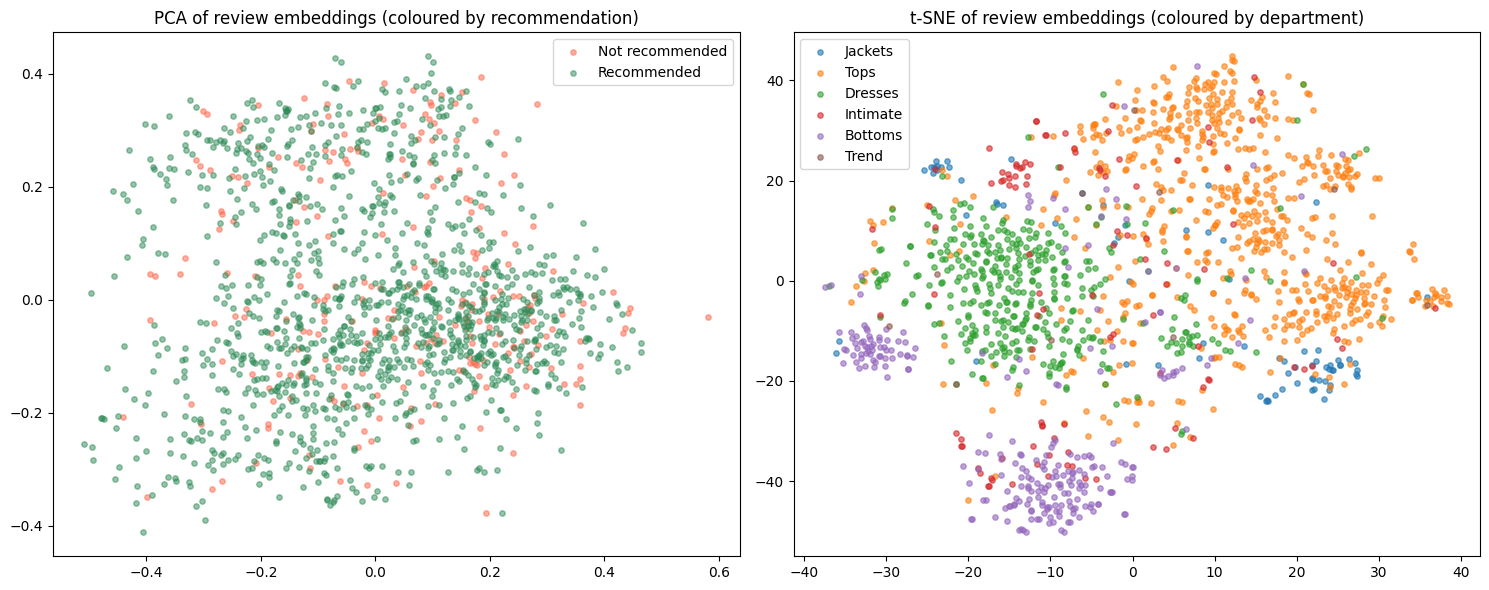

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: PCA coloured by the recommended label.
for label, color, name in [(0, "tomato", "Not recommended"), (1, "seagreen", "Recommended")]:
    part = embed_sample[embed_sample["recommended_ind"] == label]
    axes[0].scatter(part["pca_x"], part["pca_y"], c=color, label=name, alpha=0.5, s=15)
axes[0].set_title("PCA of review embeddings (coloured by recommendation)")
axes[0].legend()

# Plot 2: t-SNE coloured by department.
for dept in embed_sample["department_name"].dropna().unique():
    part = embed_sample[embed_sample["department_name"] == dept]
    axes[1].scatter(part["tsne_x"], part["tsne_y"], label=dept, alpha=0.6, s=15)
axes[1].set_title("t-SNE of review embeddings (coloured by department)")
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.5 Retrieval demo

This is a simple customer-support case. A new complaint arrives as free text. I turn it into a vector with the same model and return the most similar old reviews.

In [43]:
# Find the reviews that are most similar to a query.
def retrieve_similar_reviews(query_text, top_k=3):
    # Turn the query into a vector.
    query_vector = sbert_model.encode([query_text])
    # Cosine similarity with every review in the sample.
    sims = cosine_similarity(query_vector, sbert_embeddings)[0]
    # Take the top_k highest scores.
    top_idx = np.argsort(sims)[::-1][:top_k]
    result = embed_sample.iloc[top_idx][["text", "recommended_ind", "department_name"]].copy()
    result["similarity"] = sims[top_idx].round(3)
    return result

pd.set_option("display.max_colwidth", 200)

query_1 = "the fabric felt cheap and it did not fit true to size"
print("Query:", query_1)
display(retrieve_similar_reviews(query_1))

Query: the fabric felt cheap and it did not fit true to size


,text,recommended_ind,department_name,similarity
1475,"I bought this on sale thinking it was a great deal, but when it came in i found it to fit like a totally unflattering sack. the pattern didn't help anything, looking totally faded and washed out.....",0,Dresses,0.671
1265,Bought this on a whim and it exceeded my expectations. i didn't know what to expect with the quality of the fabric but this is incredibly soft and warm. haven't worn it outside yet but i can see t...,1,Tops,0.637
1243,Purchased this dress for a garden wedding and received so many compliments. the print is very lovely and the fit was true to size. i was mildly thrown off by the waffle texture of the material as ...,1,Dresses,0.623


In [44]:
# A second query about something this dataset probably does not cover much.
query_2 = "the delivery took forever and customer service was unhelpful"
print("Query:", query_2)
display(retrieve_similar_reviews(query_2))

Query: the delivery took forever and customer service was unhelpful


,text,recommended_ind,department_name,similarity
1375,"Very disappointed that i ordered this dress and a large was too big. returned and asked for an exchange to a size medium, it was apparently not available in the medium, i was charged a 5.95 fee fo...",1,Dresses,0.285
706,Bells out to much i had to send it back,1,Tops,0.278
111,"Just received this, been eyeing it and with free shipping and 15% off (due to online survey i took) i bought it. it's flattering, the color and design is very pretty. i just really like it!",1,Dresses,0.258


### Minimum score

A support team should not trust a weak match. I add a minimum similarity score. Below it, the system says that there is no close match. I chose 0.4 after looking at the scores of the two queries above.

In [45]:
# Show the best match only when it is close enough.
MIN_SCORE = 0.4

for query in [query_1, query_2]:
    result = retrieve_similar_reviews(query)
    best_score = result["similarity"].iloc[0]
    print("Query:", query)
    if best_score < MIN_SCORE:
        print(f"  No close match (best similarity {best_score})\n")
    else:
        print(f"  Best match ({best_score}): {result['text'].iloc[0][:200]}\n")

Query: the fabric felt cheap and it did not fit true to size
  Best match (0.6710000038146973): I bought this on sale thinking it was a great deal, but when it came in i found it to fit like a totally unflattering sack. the pattern didn't help anything, looking totally faded and washed out...the

Query: the delivery took forever and customer service was unhelpful
  No close match (best similarity 0.2849999964237213)



In [46]:
# Same query, but with the averaged GloVe vectors instead.
query_vec = average_glove_vector(nltk_preprocess(query_1)).reshape(1, -1)
glove_sims = cosine_similarity(query_vec, glove_matrix)[0]
top_idx = np.argsort(glove_sims)[::-1][:3]

print("Query:", query_1)
print("Top 3 with averaged GloVe vectors:")
for idx in top_idx:
    print(f"  ({glove_sims[idx]:.3f}) {embed_sample.loc[idx, 'text'][:200]}")

Query: the fabric felt cheap and it did not fit true to size
Top 3 with averaged GloVe vectors:
  (0.969) Wanted to love this dress. the fabric is very nice, pretty colors, great quality and style. it just didn't work for my body type. it would fit great on someone with narrower shoulders. probably want t
  (0.966) The weight of this denim is perfect, thin enough for a nice drape and wearability for all seasons but still thick enough to be structured. though there is absolutely no stretch, which is probably why 
  (0.965) I know this is labeled under activewear, but the fabric is a dream, it's incredibly flattering and could absolutely be worn in any outfit! i just bought the moss and may end up getting the other color


### Test: do the neighbours of a complaint also tend to be complaints?

Two queries are only examples. Here I use 50 not recommended reviews of the sample as queries and look at their 3 nearest other reviews. If the vectors capture complaint-like meaning, these neighbours should be complaints more often than a random review is (the base rate).

In [47]:
labels = embed_sample["recommended_ind"].values

query_positions = np.where(labels == 0)[0][:50]

def complaint_share_in_top3(embeddings):
    hits = 0
    total = 0
    for pos in query_positions:
        sims = cosine_similarity([embeddings[pos]], embeddings)[0]
        sims[pos] = -1
        top3 = np.argsort(sims)[::-1][:3]
        hits += (labels[top3] == 0).sum()
        total += 3
    return hits / total

neighbour_table = pd.DataFrame({
    "Vectors": ["Sentence-Transformer", "Averaged GloVe", "Random review (base rate)"],
    "Share of top-3 neighbours that are complaints": [
        round(complaint_share_in_top3(sbert_embeddings), 3),
        round(complaint_share_in_top3(glove_matrix), 3),
        round((labels == 0).mean(), 3),
    ],
})
display(neighbour_table)

,Vectors,Share of top-3 neighbours that are complaints
0,Sentence-Transformer,0.307
1,Averaged GloVe,0.260
2,Random review (base rate),0.177


## Task 4: Fine-Tuning a Transformer

**Model:** `distilbert-base-uncased`. DistilBERT is a smaller and faster version of BERT. It has about 66 million parameters, so it fits on the T4 GPU in Colab.

**Plan:**

1. Take a sample of 4,000 reviews and split it into train, validation and test sets.
2. Tokenize the text with `AutoTokenizer`.
3. Fine-tune with the Hugging Face `Trainer`.
4. Keep the **best** checkpoint (by validation macro F1) and save it.
5. Test it and compare it with the classical baseline **on the same test set**.

**Batch size.** I use `per_device_train_batch_size=16` for training and 32 for evaluation. With `max_length=128`. I also switch on `fp16` (mixed precision), which makes training faster.

In [48]:
# Import the Hugging Face tools.
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(SEED)

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128
print("Model:", MODEL_NAME)

Model: distilbert-base-uncased


In [49]:
# A random sample of 4,000 reviews.
TRANSFORMER_SAMPLE_SIZE = 4000
sample_df = df.sample(n=TRANSFORMER_SAMPLE_SIZE, random_state=SEED).reset_index(drop=True)

# First split: 20% for the test set.
trainval_df, test_df = train_test_split(
    sample_df, test_size=0.2, stratify=sample_df["recommended_ind"], random_state=SEED
)
# Second split: 12.5% of the rest for validation (this is 10% of all the data).
train_df, val_df = train_test_split(
    trainval_df, test_size=0.125, stratify=trainval_df["recommended_ind"], random_state=SEED
)

print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

# Turn the tables into Hugging Face datasets (the label column must be called "label").
def make_dataset(frame):
    return Dataset.from_dict({
        "text": frame["text"].tolist(),
        "label": frame["recommended_ind"].tolist(),
    })

train_ds = make_dataset(train_df)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

Train: 2800 | Validation: 400 | Test: 800


### Tokenization

`AutoTokenizer` loads the right tokenizer for the model name automatically. The transformer cannot read words. It reads token IDs, so the tokenizer splits the text into word pieces and maps each piece to an ID. Below is one example.

In [50]:
# Load the tokenizer that belongs to DistilBERT.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example_text = "The dress was lovely but it did not fit."
encoded = tokenizer(example_text)

print("Tokens   :", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("Input IDs:", encoded["input_ids"])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokens   : ['[CLS]', 'the', 'dress', 'was', 'lovely', 'but', 'it', 'did', 'not', 'fit', '.', '[SEP]']
Input IDs: [101, 1996, 4377, 2001, 8403, 2021, 2009, 2106, 2025, 4906, 1012, 102]


In [51]:
# Function that tokenizes a batch of reviews.
def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

# Apply it to the three datasets.
tokenized_train = train_ds.map(tokenize_batch, batched=True)
tokenized_val = val_ds.map(tokenize_batch, batched=True)
tokenized_test = test_ds.map(tokenize_batch, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print(tokenized_train)

Map:   0%|          | 0/2800 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2800
})


### Model and training settings

In [52]:
# Names for the two classes.
id2label = {0: "Not recommended", 1: "Recommended"}
label2id = {"Not recommended": 0, "Recommended": 1}

# Load DistilBERT with a new classification layer on top.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 66,955,010


In [53]:
# Function that calculates the metrics after every epoch.
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted")
    macro_f1 = precision_recall_fscore_support(labels, preds, average="macro")[2]
    return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1, "macro_f1": macro_f1}

USE_FP16 = torch.cuda.is_available()

training_args = TrainingArguments(
    output_dir="distilbert_feedback_checkpoints",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    logging_steps=25,
    fp16=USE_FP16,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
print("Trainer ready. fp16:", USE_FP16)

Trainer ready. fp16: True


I use macro F1 to choose the best checkpoint, not accuracy. The data is unbalanced, and macro F1 gives the same weight to the small "not recommended" class.

In [54]:
# Fine-tune the model and measure the time.
start_time = time.time()
train_result = trainer.train()
training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds:.0f} seconds")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.265191,0.254863,0.887500,0.883824,0.887500,0.885263,0.804090
2,0.180351,0.335759,0.880000,0.871460,0.880000,0.870321,0.767880
3,0.137179,0.337057,0.887500,0.881605,0.887500,0.883098,0.797094


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training time: 60 seconds
Best checkpoint: distilbert_feedback_checkpoints/checkpoint-175
Best validation macro F1: 0.8040901620609715


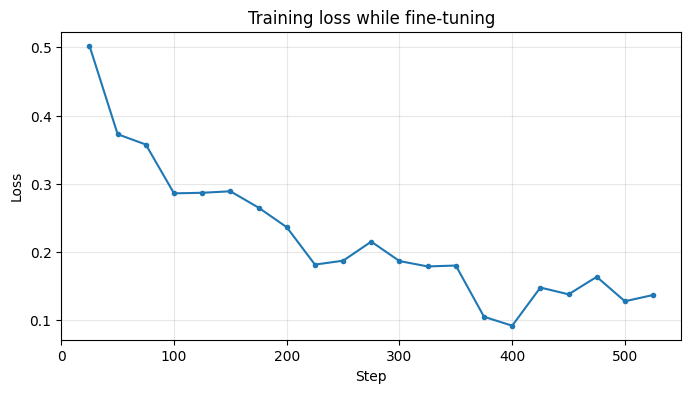

,epoch,eval_loss,eval_accuracy,eval_macro_f1
7,1.0,0.2549,0.8875,0.8041
15,2.0,0.3358,0.8800,0.7679
23,3.0,0.3371,0.8875,0.7971


In [55]:
# Look at the training history (loss and validation metrics).
history = pd.DataFrame(trainer.state.log_history)

# Training loss by step.
train_logs = history[history["loss"].notna()] if "loss" in history else history.iloc[0:0]
plt.figure(figsize=(8, 4))
plt.plot(train_logs["step"], train_logs["loss"], marker="o", markersize=3)
plt.title("Training loss while fine-tuning")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.show()

# Validation metrics by epoch.
eval_logs = history[history["eval_loss"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
display(eval_logs.round(4))

In [56]:
# Save the best model and the tokenizer to a folder.
BEST_MODEL_DIR = "best_distilbert_feedback"
trainer.save_model(BEST_MODEL_DIR)
tokenizer.save_pretrained(BEST_MODEL_DIR)
print("Saved the best model to:", BEST_MODEL_DIR)

# Check that the saved model loads again.
reloaded_model = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR)
print("Reloaded model labels:", reloaded_model.config.id2label)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved the best model to: best_distilbert_feedback


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Reloaded model labels: {0: 'Not recommended', 1: 'Recommended'}


Because I used `load_best_model_at_end=True`, the model inside `trainer` is already the best epoch, and this is the one that I saved.

### Evaluation on the test set

----- Fine-tuned DistilBERT -----
Accuracy : 0.889
Precision: 0.898 (weighted)
Recall   : 0.889 (weighted)
F1       : 0.892 (weighted)
Macro F1 : 0.825

                 precision    recall  f1-score   support

Not recommended       0.67      0.78      0.72       146
    Recommended       0.95      0.91      0.93       654

       accuracy                           0.89       800
      macro avg       0.81      0.85      0.82       800
   weighted avg       0.90      0.89      0.89       800



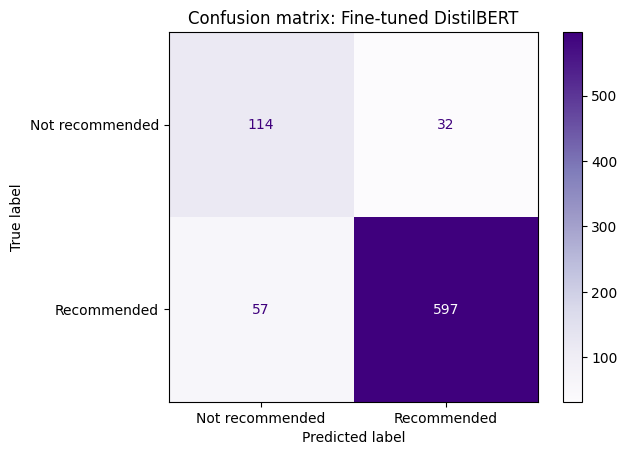

In [57]:
# Predict on the test set.
test_output = trainer.predict(tokenized_test)
bert_preds = np.argmax(test_output.predictions, axis=-1)
bert_true = test_df["recommended_ind"].values

bert_results = evaluate_model("Fine-tuned DistilBERT", bert_true, bert_preds, cmap="Purples")

### Transformer vs classical model

The classical model in Task 2 was trained on about 18,000 reviews. DistilBERT only saw 2,800. To compare fairly, I train Logistic Regression again on **the same 2,800 training reviews** and test both models on **the same 800 test reviews**.

Logistic Regression in Task 2 used balanced class weights, but DistilBERT is trained without class weights. So I train Logistic Regression two ways: with balanced class weights, and without them.

----- Logistic Regression (same 2,800 reviews) -----
Accuracy : 0.868
Precision: 0.893 (weighted)
Recall   : 0.868 (weighted)
F1       : 0.875 (weighted)
Macro F1 : 0.805

                 precision    recall  f1-score   support

Not recommended       0.60      0.83      0.70       146
    Recommended       0.96      0.88      0.92       654

       accuracy                           0.87       800
      macro avg       0.78      0.85      0.81       800
   weighted avg       0.89      0.87      0.88       800



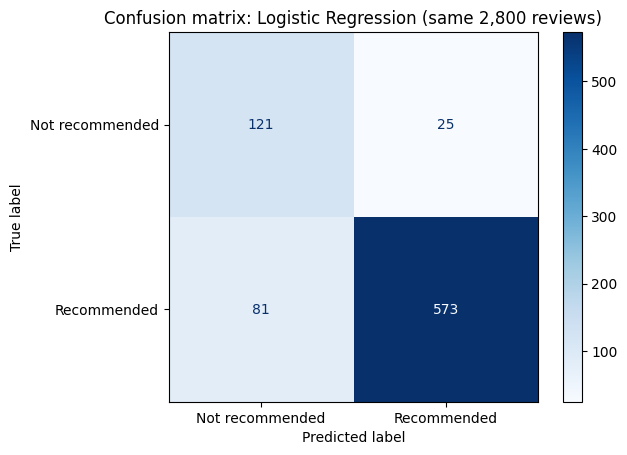

In [58]:
# Logistic Regression on exactly the same train and test reviews as DistilBERT.
small_tfidf = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)
Xs_train = small_tfidf.fit_transform(train_df["text"])
Xs_test = small_tfidf.transform(test_df["text"])

start_time = time.time()
small_logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)
small_logreg.fit(Xs_train, train_df["recommended_ind"])
logreg_seconds = time.time() - start_time

small_preds = small_logreg.predict(Xs_test)
small_results = evaluate_model("Logistic Regression (same 2,800 reviews)", bert_true, small_preds)

----- Logistic Regression, no class weights (same 2,800 reviews) -----
Accuracy : 0.849
Precision: 0.857 (weighted)
Recall   : 0.849 (weighted)
F1       : 0.806 (weighted)
Macro F1 : 0.616

                 precision    recall  f1-score   support

Not recommended       0.90      0.19      0.32       146
    Recommended       0.85      1.00      0.91       654

       accuracy                           0.85       800
      macro avg       0.87      0.59      0.62       800
   weighted avg       0.86      0.85      0.81       800



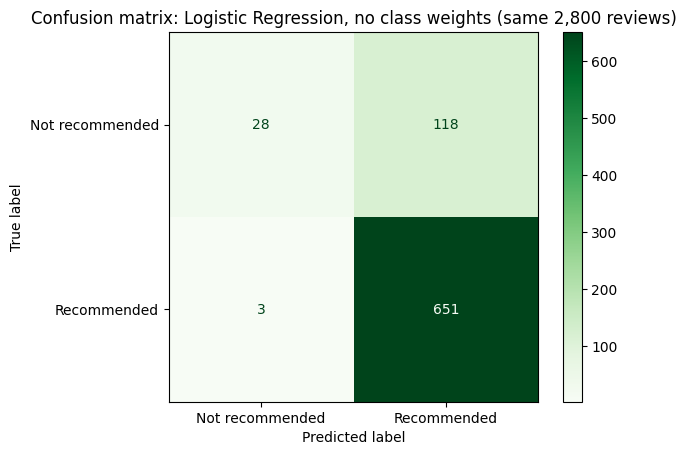

In [59]:
# Logistic Regression without class weights.
start_time = time.time()
lr_noweight = LogisticRegression(max_iter=1000, random_state=SEED)
lr_noweight.fit(Xs_train, train_df["recommended_ind"])
lr_noweight_seconds = time.time() - start_time

noweight_preds = lr_noweight.predict(Xs_test)
noweight_results = evaluate_model("Logistic Regression, no class weights (same 2,800 reviews)", bert_true, noweight_preds, cmap="Greens")

### Speed and memory

I measure how long each model needs to predict the 800 test reviews. For Logistic Regression this includes the TF-IDF step. For DistilBERT I use `trainer.predict`. I also read the peak GPU memory, which includes the training run.

In [60]:
# Time the prediction of the 800 test reviews with Logistic Regression.
start_time = time.time()
_ = small_logreg.predict(small_tfidf.transform(test_df["text"]))
lr_predict_seconds = time.time() - start_time

# Time the prediction of the same reviews with DistilBERT.
if torch.cuda.is_available():
    torch.cuda.synchronize()
start_time = time.time()
_ = trainer.predict(tokenized_test)
if torch.cuda.is_available():
    torch.cuda.synchronize()
bert_predict_seconds = time.time() - start_time

# Peak GPU memory.
if torch.cuda.is_available():
    gpu_memory_gb = torch.cuda.max_memory_allocated() / 1e9
    gpu_memory_text = f"{gpu_memory_gb:.1f} GB peak GPU memory (T4)"
else:
    gpu_memory_text = "No GPU used"

print(f"Logistic Regression: {lr_predict_seconds:.2f} seconds for {len(test_df)} reviews")
print(f"DistilBERT         : {bert_predict_seconds:.2f} seconds for {len(test_df)} reviews")
print("DistilBERT memory  :", gpu_memory_text)

Logistic Regression: 0.12 seconds for 800 reviews
DistilBERT         : 0.85 seconds for 800 reviews
DistilBERT memory  : 1.5 GB peak GPU memory (T4)


In [61]:
# Put everything in one comparison table.

def complaint_scores(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None)
    return f"{precision[0]:.2f} / {recall[0]:.2f}"

comparison_table = pd.DataFrame([
    {
        "Model": "Logistic Regression, balanced weights, full train set",
        "Test set": "Task 2 test set (about 4,500 reviews)",
        "Accuracy": round(logreg_results["accuracy"], 3),
        "Macro F1": round(logreg_results["macro_f1"], 3),
        "Complaint precision / recall": complaint_scores(y_test, logreg_preds),
        "Training time": f"{logreg_full_seconds:.1f} seconds (CPU)",
        "Model complexity": f"{len(tfidf.get_feature_names_out()):,} features, one weight each",
        "Prediction time": "not measured",
        "Interpretability": "High: I can list the words behind each decision",
        "Resource needs": "Normal CPU, very little memory",
        "Deployment practicality": "Easy to deploy and to retrain often",
    },
    {
        "Model": "Logistic Regression, balanced weights, same 2,800 reviews",
        "Test set": "Task 4 test set (800 reviews)",
        "Accuracy": round(small_results["accuracy"], 3),
        "Macro F1": round(small_results["macro_f1"], 3),
        "Complaint precision / recall": complaint_scores(bert_true, small_preds),
        "Training time": f"{logreg_seconds:.1f} seconds (CPU)",
        "Model complexity": f"{len(small_tfidf.get_feature_names_out()):,} features, one weight each",
        "Prediction time": f"{lr_predict_seconds:.2f} seconds for 800 reviews",
        "Interpretability": "High: I can list the words behind each decision",
        "Resource needs": "Normal CPU, very little memory",
        "Deployment practicality": "Easy to deploy and to retrain often",
    },
    {
        "Model": "Logistic Regression, no class weights, same 2,800 reviews",
        "Test set": "Task 4 test set (800 reviews)",
        "Accuracy": round(noweight_results["accuracy"], 3),
        "Macro F1": round(noweight_results["macro_f1"], 3),
        "Complaint precision / recall": complaint_scores(bert_true, noweight_preds),
        "Training time": f"{lr_noweight_seconds:.1f} seconds (CPU)",
        "Model complexity": f"{len(small_tfidf.get_feature_names_out()):,} features, one weight each",
        "Prediction time": "not measured",
        "Interpretability": "High: I can list the words behind each decision",
        "Resource needs": "Normal CPU, very little memory",
        "Deployment practicality": "Easy to deploy and to retrain often",
    },
    {
        "Model": "Fine-tuned DistilBERT",
        "Test set": "Task 4 test set (800 reviews)",
        "Accuracy": round(bert_results["accuracy"], 3),
        "Macro F1": round(bert_results["macro_f1"], 3),
        "Complaint precision / recall": complaint_scores(bert_true, bert_preds),
        "Training time": f"{training_seconds:.0f} seconds ({DEVICE})",
        "Model complexity": f"{total_params:,} parameters",
        "Prediction time": f"{bert_predict_seconds:.2f} seconds for 800 reviews",
        "Interpretability": "Low: hard to explain a single decision",
        "Resource needs": gpu_memory_text,
        "Deployment practicality": "Heavier to host, and a GPU helps for speed",
    },
])
display(comparison_table.set_index("Model").T)

Model,"Logistic Regression, balanced weights, full train set","Logistic Regression, balanced weights, same 2,800 reviews","Logistic Regression, no class weights, same 2,800 reviews",Fine-tuned DistilBERT
Test set,"Task 2 test set (about 4,500 reviews)",Task 4 test set (800 reviews),Task 4 test set (800 reviews),Task 4 test set (800 reviews)
Accuracy,0.891,0.868,0.849,0.889
Macro F1,0.837,0.805,0.616,0.825
Complaint precision / recall,0.65 / 0.87,0.60 / 0.83,0.90 / 0.19,0.67 / 0.78
Training time,1.0 seconds (CPU),0.1 seconds (CPU),0.1 seconds (CPU),60 seconds (cuda)
Model complexity,"8,000 features, one weight each","8,000 features, one weight each","8,000 features, one weight each","66,955,010 parameters"
Prediction time,not measured,0.12 seconds for 800 reviews,not measured,0.85 seconds for 800 reviews
Interpretability,High: I can list the words behind each decision,High: I can list the words behind each decision,High: I can list the words behind each decision,Low: hard to explain a single decision
Resource needs,"Normal CPU, very little memory","Normal CPU, very little memory","Normal CPU, very little memory",1.5 GB peak GPU memory (T4)
Deployment practicality,Easy to deploy and to retrain often,Easy to deploy and to retrain often,Easy to deploy and to retrain often,"Heavier to host, and a GPU helps for speed"


### DistilBERT mistakes

I compare the mistakes of DistilBERT and of the small Logistic Regression on the same 800 test reviews.

In [62]:
# One table with the true label and both predictions.
compare = test_df.reset_index(drop=True).copy()
compare["true"] = compare["recommended_ind"]
compare["bert_pred"] = bert_preds
compare["lr_pred"] = small_preds
compare["words"] = compare["text"].str.split().str.len()

bert_wrong = compare["bert_pred"] != compare["true"]
lr_wrong = compare["lr_pred"] != compare["true"]

print("Both models wrong     :", (bert_wrong & lr_wrong).sum())
print("Only DistilBERT wrong :", (bert_wrong & ~lr_wrong).sum())
print("Only Logistic Reg. wrong:", (~bert_wrong & lr_wrong).sum())

# Are the mistakes related to the review length?
print("\nAverage words per review, DistilBERT wrong :", round(compare[bert_wrong]["words"].mean(), 1))
print("Average words per review, DistilBERT correct:", round(compare[~bert_wrong]["words"].mean(), 1))

def show_examples(frame, title, n=3):
    print("\n===", title, "===")
    if len(frame) == 0:
        print("No examples.")
        return
    for _, row in frame.sample(min(n, len(frame)), random_state=7).iterrows():
        print(f"- true={row['true']} DistilBERT={row['bert_pred']} LogReg={row['lr_pred']}")
        print(" ", row["text"][:400], "\n")

show_examples(compare[bert_wrong & lr_wrong], "BOTH MODELS WRONG")
show_examples(compare[bert_wrong & ~lr_wrong], "ONLY DISTILBERT WRONG")

Both models wrong     : 47
Only DistilBERT wrong : 42
Only Logistic Reg. wrong: 59

Average words per review, DistilBERT wrong : 70.1
Average words per review, DistilBERT correct: 61.6

=== BOTH MODELS WRONG ===
- true=0 DistilBERT=1 LogReg=1
  I got this in the green color. it's a beautiful color, soft to the touch. i agree with other reviewers that it seems very delicate. i don't mind dry-cleaning my sweaters, so that's not the issue. the problem is that a. it runs huge - i got the small and it swims on me. i tend to run between small and medium in tops - very unusual to have a small be so big on me and b. the slits go even higher than 

- true=1 DistilBERT=0 LogReg=0
  The dress looks beautiful online, and fits the model great. when i got mine, the arm holes were incredibly too tight. everything else about the fit was perfect--length, bust/waist-- but i could barely drop my arms down when i tried it on. unfortunately it will be going back. 

- true=1 DistilBERT=0 LogReg=0
  I ordere

### Check: is the DistilBERT result stable? (different seeds)

DistilBERT was trained once with seed 42. I train it three more times with other seeds. The data split and all settings stay the same, so only the random start changes. This takes a few minutes on the T4.

In [63]:
# Function that trains DistilBERT with one seed and returns the test scores.
def train_with_seed(seed):
    set_seed(seed)
    new_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id
    ).to(DEVICE)

    seed_args = TrainingArguments(
        output_dir=f"distilbert_seed_{seed}",
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=3,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=25,
        fp16=USE_FP16,
        seed=seed,
        report_to="none",
    )
    seed_trainer = Trainer(
        model=new_model, args=seed_args,
        train_dataset=tokenized_train, eval_dataset=tokenized_val,
        data_collator=data_collator, compute_metrics=compute_metrics,
    )
    seed_trainer.train()

    seed_output = seed_trainer.predict(tokenized_test)
    seed_preds = np.argmax(seed_output.predictions, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(bert_true, seed_preds, average=None)
    result = {
        "Seed": seed,
        "Accuracy": round(accuracy_score(bert_true, seed_preds), 3),
        "Macro F1": round(precision_recall_fscore_support(bert_true, seed_preds, average="macro")[2], 3),
        "Complaint precision": round(precision[0], 3),
        "Complaint recall": round(recall[0], 3),
    }

    # Free the GPU memory before the next run.
    del seed_trainer, new_model
    torch.cuda.empty_cache()
    return result

# The first row is the run from above (seed 42).
precision, recall, f1, _ = precision_recall_fscore_support(bert_true, bert_preds, average=None)
seed_rows = [{"Seed": 42, "Accuracy": round(bert_results["accuracy"], 3), "Macro F1": round(bert_results["macro_f1"], 3),
              "Complaint precision": round(precision[0], 3), "Complaint recall": round(recall[0], 3)}]

for seed in [1, 2, 3]:
    seed_rows.append(train_with_seed(seed))

seed_table = pd.DataFrame(seed_rows)
display(seed_table)
print("Mean macro F1:", round(seed_table["Macro F1"].mean(), 3), "| Std:", round(seed_table["Macro F1"].std(), 3))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.224280,0.275939,0.892500,0.886340,0.892500,0.886778,0.801292
2,0.184669,0.313238,0.885000,0.877491,0.885000,0.877579,0.783336
3,0.118412,0.348836,0.890000,0.886014,0.890000,0.887476,0.807347


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,Seed,Accuracy,Macro F1,Complaint precision,Complaint recall
0,42,0.889,0.825,0.667,0.781
1,1,0.925,0.875,0.791,0.801
2,2,0.919,0.864,0.776,0.781
3,3,0.915,0.856,0.775,0.753


Mean macro F1: 0.855 | Std: 0.021


## Task 5: Responsible NLP for Customer Feedback Analytics

 A fairness check and a decision-support table. The written discussion of risks, regulation and the RAG trend is in the report.

### 5.1 A fairness check on the Task 2 model


An average accuracy can hide a group where the model is much worse. I split the Task 2 test set by `department_name` and calculate two numbers for each department: the accuracy, and the complaint recall. The second number matters most, because a missed complaint is the costly mistake.

In [64]:
# Take the department of every review in the Task 2 test set.
test_meta = df.loc[X_test_text.index, ["department_name"]].copy()
test_meta["true_label"] = y_test.values
test_meta["predicted_label"] = logreg_preds

# Count the reviews per department in the TRAIN set too.
train_dept_counts = df.loc[X_train_text.index, "department_name"].value_counts()

rows = []
for dept, group in test_meta.groupby("department_name"):
    # Accuracy in this department.
    accuracy = (group["true_label"] == group["predicted_label"]).mean()
    # Complaint recall: of the real complaints, how many were predicted as complaints?
    complaints = group[group["true_label"] == 0]
    if len(complaints) > 0:
        complaint_recall = (complaints["predicted_label"] == 0).mean()
    else:
        complaint_recall = np.nan
    rows.append({
        "department": dept,
        "train reviews": train_dept_counts.get(dept, 0),
        "test reviews": len(group),
        "real complaints in test": len(complaints),
        "accuracy": round(accuracy, 3),
        "complaint recall": round(complaint_recall, 3),
    })

fairness_check = pd.DataFrame(rows).set_index("department").sort_values("accuracy")
display(fairness_check)

,train reviews,test reviews,real complaints in test,accuracy,complaint recall
department,,,,,
Bottoms,2911,751,124,0.885,0.774
Dresses,4973,1172,219,0.887,0.895
Tops,8032,2029,383,0.889,0.893
Trend,98,20,5,0.900,0.800
Intimate,1294,359,55,0.914,0.873
Jackets,804,198,34,0.919,0.853


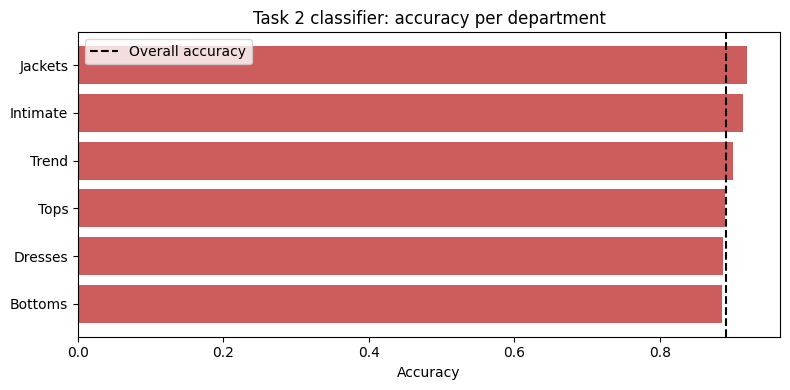

Lowest accuracy : Bottoms (0.885), 2911 train reviews
Highest accuracy: Jackets (0.919), 804 train reviews
Lowest complaint recall: Bottoms (0.774)


In [65]:
# Bar chart of the accuracy per department.
plt.figure(figsize=(8, 4))
plt.barh(fairness_check.index, fairness_check["accuracy"], color="indianred")
plt.axvline(logreg_results["accuracy"], color="black", linestyle="--", label="Overall accuracy")
plt.title("Task 2 classifier: accuracy per department")
plt.xlabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Main findings, calculated from the table.
worst = fairness_check["accuracy"].idxmin()
best = fairness_check["accuracy"].idxmax()
print(f"Lowest accuracy : {worst} ({fairness_check.loc[worst, 'accuracy']}), "
      f"{int(fairness_check.loc[worst, 'train reviews'])} train reviews")
print(f"Highest accuracy: {best} ({fairness_check.loc[best, 'accuracy']}), "
      f"{int(fairness_check.loc[best, 'train reviews'])} train reviews")

recall_table = fairness_check["complaint recall"].dropna()
print(f"Lowest complaint recall: {recall_table.idxmin()} ({recall_table.min()})")

 The table below repeats the check for the Task 4 test set, for both DistilBERT and Logistic Regression. The test set has only 800 reviews, so some departments have very few reviews. I treat these numbers as a hint, not as proof.

In [66]:
# Accuracy per department for both models on the Task 4 test set.
dept_compare = test_df.reset_index(drop=True)[["department_name"]].copy()
dept_compare["bert_correct"] = (bert_preds == bert_true)
dept_compare["logreg_correct"] = (small_preds == bert_true)

dept_table = dept_compare.groupby("department_name").agg(
    reviews=("bert_correct", "size"),
    bert_accuracy=("bert_correct", "mean"),
    logreg_accuracy=("logreg_correct", "mean"),
).round(3)
display(dept_table)

,reviews,bert_accuracy,logreg_accuracy
department_name,,,
Bottoms,126,0.905,0.865
Dresses,203,0.847,0.837
Intimate,52,0.904,0.942
Jackets,39,0.923,0.974
Tops,378,0.899,0.862
Trend,2,1.000,1.000


### A word check

Bottoms had the lowest complaint recall in the check above. I compare the words of the Bottoms complaints that the model missed with the words of the complaints that it found. I also count how many reviews in each group contain a typical complaint word from the Task 2 list.

In [67]:
# Real complaints in Bottoms (Task 2 test set), split into missed and caught.
bottoms = test_meta[(test_meta["department_name"] == "Bottoms") & (test_meta["true_label"] == 0)]
missed_idx = bottoms[bottoms["predicted_label"] == 1].index
caught_idx = bottoms[bottoms["predicted_label"] == 0].index

def top_words(index_list, n=12):
    words = [tok for tokens in df.loc[index_list, "nltk_tokens"] for tok in tokens]
    return Counter(words).most_common(n)

print("Missed Bottoms complaints:", len(missed_idx))
print(top_words(missed_idx))
print("\nCaught Bottoms complaints:", len(caught_idx))
print(top_words(caught_idx))

complaint_words = {"disappointed", "unflattering", "returned", "cheap", "returning", "huge"}
for name, idx in [("missed", missed_idx), ("caught", caught_idx)]:
    share = np.mean([any(w in complaint_words for w in df.loc[i, "nltk_tokens"]) for i in idx])
    print(f"\nShare of {name} complaints with a typical complaint word: {share:.1%}")

Missed Bottoms complaints: 28
[('jean', 23), ("n't", 22), ('size', 20), ('fit', 18), ('skirt', 14), ('not', 13), ('small', 12), ('look', 11), ('pant', 10), ('back', 9), ('great', 8), ('material', 7)]

Caught Bottoms complaints: 96
[('not', 59), ('pant', 45), ("n't", 45), ('skirt', 41), ('would', 38), ('fit', 37), ('size', 36), ('like', 35), ('wear', 32), ('even', 30), ('way', 29), ('waist', 28)]

Share of missed complaints with a typical complaint word: 7.1%

Share of caught complaints with a typical complaint word: 29.2%


### From model output to decision support

A business needs more than a score. For every department, I show the complaint rate in all reviews, the real and the predicted complaint rate on the Task 2 test set, and the word pairs that are most typical for the complaints of this department.

In [68]:
# Complaint reviews of all departments, as strings of tokens.
complaints = df[df["recommended_ind"] == 0]
complaint_texts = [" ".join(tokens) for tokens in complaints["nltk_tokens"]]

# Count in how many complaints each word pair appears.
pair_counter = CountVectorizer(ngram_range=(2, 2), token_pattern=r"\S+", min_df=5, binary=True)
pair_matrix = pair_counter.fit_transform(complaint_texts)
pair_names = pair_counter.get_feature_names_out()

decision_rows = []
for dept, group in test_meta.groupby("department_name"):
    dept_reviews = df[df["department_name"] == dept]
    all_rate = (dept_reviews["recommended_ind"] == 0).mean()
    real_rate = (group["true_label"] == 0).mean()
    predicted_rate = (group["predicted_label"] == 0).mean()

    # Word pairs that are much more common in this department's complaints than in the other complaints.
    in_dept = (complaints["department_name"] == dept).values
    count_in = np.asarray(pair_matrix[in_dept].sum(axis=0)).ravel()
    count_out = np.asarray(pair_matrix[~in_dept].sum(axis=0)).ravel()
    share_in = count_in / in_dept.sum()
    share_out = count_out / (~in_dept).sum()
    score = (share_in + 0.001) / (share_out + 0.001)
    score[count_in < 3] = 0
    best = np.argsort(score)[::-1][:3]
    themes = [pair_names[i] for i in best if score[i] > 0]

    decision_rows.append({
        "Department": dept,
        "All reviews": len(dept_reviews),
        "Complaint rate, all reviews": round(all_rate, 3),
        "Test reviews": len(group),
        "Real rate, test": round(real_rate, 3),
        "Predicted rate, test": round(predicted_rate, 3),
        "Typical complaint word pairs": ", ".join(themes),
    })

decision_table = pd.DataFrame(decision_rows).sort_values("Complaint rate, all reviews", ascending=False)
display(decision_table)

,Department,All reviews,"Complaint rate, all reviews",Test reviews,"Real rate, test","Predicted rate, test",Typical complaint word pairs
5,Trend,118,0.254,20,0.250,0.250,"dress pretty, like dress, usually wear"
1,Dresses,6145,0.195,1172,0.187,0.261,"dress fit, love dress, dress look"
4,Tops,10061,0.189,2029,0.189,0.259,"maternity top, sweater not, ordered top"
3,Jackets,1002,0.167,198,0.172,0.202,"room spare, fall apart, tight chest"
2,Intimate,1653,0.154,359,0.153,0.201,"bathing suit, love suit, cup size"
0,Bottoms,3662,0.150,751,0.165,0.205,"pant fit, another pair, loved pant"


## Interactive Dashboard (Gradio)

This part is a bonus. I build a small Gradio app to test the models by hand. Paste any raw review, typos included, and the app shows the Task 2 prediction, the Task 4 prediction (saved DistilBERT) and the three most similar reviews from Task 3. The models do their own cleaning, so the text does not need to be cleaned first.

In [69]:
import gradio as gr

# Load the saved best model from disk, as a deployed app would do
app_tokenizer = AutoTokenizer.from_pretrained(BEST_MODEL_DIR)
app_model = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR).to(DEVICE)
app_model.eval()

# Analyse one raw review
def analyse_review(review_text):
    # Stop if the box is empty
    if not review_text or not review_text.strip():
        return "Please enter a review.", "", ""

    # 1. Logistic Regression from Task 2
    vec = tfidf.transform([review_text])
    lr_pred = int(logreg.predict(vec)[0])
    lr_conf = logreg.predict_proba(vec)[0][lr_pred]
    lr_text = f"{id2label[lr_pred]} (confidence {lr_conf:.1%})"

    # 2. DistilBERT from Task 4
    inputs = app_tokenizer(review_text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(DEVICE)
    with torch.no_grad():
        logits = app_model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)[0]
    bert_pred = int(torch.argmax(probs))
    bert_text = f"{id2label[bert_pred]} (confidence {probs[bert_pred].item():.1%})"

    # 3. Most similar reviews from Task 3
    similar = retrieve_similar_reviews(review_text, top_k=3)
    similar_text = "\n\n".join(
        f"({row.similarity:.2f}) [{row.department_name}] {row.text}" for row in similar.itertuples()
    )

    return lr_text, bert_text, similar_text

with gr.Blocks(title="Customer Feedback Intelligence") as demo:
    gr.Markdown("# Customer Feedback Intelligence\nPaste a raw review to see the prediction of both models and similar past reviews.")

    review_box = gr.Textbox(lines=4, label="Paste a customer review (raw text is fine)")
    analyse_button = gr.Button("Analyse review")
    lr_box = gr.Textbox(label="Task 2: Logistic Regression")
    bert_box = gr.Textbox(label="Task 4: Fine-tuned DistilBERT")
    similar_box = gr.Textbox(label="Task 3: Similar reviews", lines=8)
    analyse_button.click(analyse_review, inputs=review_box, outputs=[lr_box, bert_box, similar_box])

demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2a24790f58c3f39eca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
